In [1]:
import sys
import time
import itertools
import pandas as pd
import os
from pathlib import Path
import numpy as np
from typing import Union
import random
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, RocCurveDisplay
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
sys.path.insert(1, '..')
from Guidestar_model.DiscretisationFunctions import *
from utilsN.FPKM_functions import *

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


In [2]:
seed = 0
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)

In [3]:
gs_main = os.path.join(main_dir, 'Data/20250728_Lm50GS_mbrain_3cT3')
GS_filepath = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_GuidestarGenes_training_set1.csv')
merfish_filepath = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_MerfishData_set1.csv')
fpkm_path = os.path.join(gs_main, 'codebook/fpkm_data.txt')
df_fpkm = pd.read_csv(fpkm_path, sep='\t', header=None, names=['genes','FPKM'])
merfish_data = pd.read_csv(merfish_filepath)
GS_genes_data = pd.read_csv(GS_filepath)
output_dir = 'benchmarking_results/'
nfovs = 86

GS_gene_list = ['Slc1a2', 'Cacna1i', 'Cacna1a']
blank_list = [i for i in GS_genes_data['gene'].unique() if i.startswith('Blank')]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'meaninten1_3_ratio_frob_clipped', 'mindist2_clipped', 'mindist3_clipped', 'size_conn']
blank_ratio = 0
merfish_ratio = None
colocal_ratio = None
bft = 0.25
if not os.path.exists(output_dir):
    os.mkdir(output_dir)

In [4]:
print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
GS_genes_data['meaninten1_3_ratio_frob'] = GS_genes_data['meaninten1_frob'] / GS_genes_data['meaninten3_frob']
temp = GS_genes_data['meaninten1_3_ratio_frob'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['meaninten1_3_ratio_frob_clipped'] = np.clip(GS_genes_data['meaninten1_3_ratio_frob'],a_min=np.min(GS_genes_data['meaninten1_3_ratio_frob']),a_max=14)

temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

merfish_data['meaninten1_3_ratio_frob'] = merfish_data['meaninten1_frob'] / merfish_data['meaninten3_frob']
temp = merfish_data['meaninten1_3_ratio_frob'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['meaninten1_3_ratio_frob_clipped'] = np.clip(merfish_data['meaninten1_3_ratio_frob'],a_min=np.min(merfish_data['meaninten1_3_ratio_frob']),a_max=14)

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# test set
testing_fovs = ['000_006','000_007','000_008','000_009','001_006','001_007','001_008','001_009',
                '002_006','002_007','002_008','002_009','003_006','003_007','003_008','003_009']
random.seed(0)
training_fovs = [i for i in GS_genes_data['fov'].unique() if i not in testing_fovs] # BRAIN
X_test = GS_genes_data[features_to_use + ['type', 'Label', 'fov', 'gene']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[GS_genes_data['fov'].isin(training_fovs)]
print('train fovs:', training_fovs)
print('test fovs:', testing_fovs)

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    # can match number of blanks to merfishonly
    # or topup merfishonly to colocalgenes with blanks
    if blank_ratio == 'match':
        colocal_diff = len(GS_df) - len(merfish_df)
        if colocal_diff < 0:
            blank_df_resampled = pd.DataFrame()
        elif colocal_diff > 0:
            blank_df_resampled =  resample(blank_df, replace = True, n_samples = int(abs(colocal_diff)), random_state=0)
        else:
            blank_df_resampled = pd.DataFrame()
    elif blank_ratio is not None and isinstance(blank_ratio, (int, np.integer))==True and len(blank_df) > int(len(merfish_df)*blank_ratio): # match blanks to merfishonly
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = pd.DataFrame()
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    elif merfish_ratio is not None and len(merfish_df) < int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = True, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    if colocal_ratio is not None and len(GS_df) > int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = False, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    elif colocal_ratio is not None and len(GS_df) < int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = True, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    else:
        GS_df_resampled = GS_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df))
    
    resampled_fov = pd.concat([GS_df, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()
# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0, n_jobs=-3, min_samples_split=0.001,
                            min_impurity_decrease=0.01, max_features=1, max_depth=12,
                            criterion='entropy', min_weight_fraction_leaf=0.175,
                            n_estimators=300, max_samples=None)
print('random forest model:', RF)

cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])

training file used: <main_dir>/Data/20250728_Lm50GS_mbrain_3cT3\output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_GuidestarGenes_training_set1.csv
train fovs: ['009_001', '003_005', '008_001', '009_009', '005_001', '007_003', '008_009', '002_003', '003_001', '004_009', '003_003', '006_007', '005_007', '005_008', '004_007', '006_009', '005_000', '004_008', '004_001', '002_005', '006_008', '000_005', '007_007', '003_002', '006_000', '008_005', '002_002', '009_007', '007_000', '005_009', '001_001', '004_003', '004_002', '002_000', '001_005', '007_002', '006_006', '006_002', '002_001', '007_001', '008_006', '008_002', '001_004', '006_001', '008_008', '007_006', '006_004', '008_003', '001_002', '004_000', '009_002', '009_008', '009_005', '007_008', '004_004', '004_005', '007_004', '005_003', '005_004', '000_004', '006_003', '008_007', '001_003', '009_006', '006_005', '009_003', '003_000', '005_005', '009_000', '009_004']
test fovs: ['000_006', '000_007', '000_008

Pipeline(steps=[('discretizer',
                 ChiMergeTransformer(allow_early_stop=True,
                                     attr_list=['meaninten1_frob',
                                                'meaninten1_3_ratio_frob_clipped',
                                                'mindist2_clipped',
                                                'mindist3_clipped',
                                                'size_conn'],
                                     hot_start_num_intervals=1000,
                                     min_intervals=2)),
                ('remove_labels',
                 <Guidestar_model.DiscretisationFunctions.columnDropperTransformer object at 0x000001F4408C02E0>),
                ('model',
                 RandomForestClassifier(criterion='entropy', max_depth=12,
                                        max_features=1,
                                        min_impurity_decrease=0.01,
                                        min_samples_split=0.001,
                                        min_weight_fraction_leaf=0.175,
                                        n_estimators=300, n_jobs=-3,
                                        random_state=0))])

### Load Polaris and MERlin results for 'precision, recall & F1' computation

In [5]:
# load the full Polaris result; subset to GS genes and blanks
polaris_main = os.path.join(gs_main, 'output/Relaxed Bernoulli_thresh0.85_GS_chrco_img_regi_no_butter2d/polaris_LM50GS_result_edgecrop/')
polaris_gs_data = pd.read_csv(os.path.join(polaris_main, 'colocalization_output_20250929_1705_final/Polaris_LM50GS_86FOVs_GuidestarGenes_training.csv'))
polaris_gs_data = polaris_gs_data.loc[polaris_gs_data['gene'].isin(GS_gene_list+blank_list)]

In [6]:
# compute precision, recall and f1
model_precision = []
model_recall = []
model_f1 = []
model_auroc = []
bft_precision = []
bft_recall = []
bft_f1 = []
bft_auroc = []

polaris_precision = []
polaris_recall = []
polaris_f1 = []
polaris_auroc = []

for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    polaris_subset = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov] 
    polaris_subset['pred'] = (polaris_subset['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris

    if test_fov == testing_fovs[0]:
        print('Polaris predictions (prob >= 0.95) for fov', test_fov)
        print(polaris_subset[['gene','Label','probability','pred']].loc[polaris_subset['gene'].isin(GS_gene_list)])
    polaris_precision.append(precision_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_recall.append(recall_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_f1.append(f1_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_auroc.append(roc_auc_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['probability'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    
    model_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                           Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                             Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    bft_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                         Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                           Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   1 - Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    

results_df = pd.DataFrame({'fov': testing_fovs, 'model_precision': model_precision, 'model_recall': model_recall,
                           'model_f1': model_f1, 'model_auroc': model_auroc,
                           'bft_precision': bft_precision, 'bft_recall': bft_recall,
                           'bft_f1': bft_f1, 'bft_auroc': bft_auroc,
                           'polaris_precision': polaris_precision, 'polaris_recall': polaris_recall,
                           'polaris_f1': polaris_f1, 'polaris_auroc': polaris_auroc})
results_df.to_csv(os.path.join(output_dir,'testset_results_lm50gs_benchmark_p_edge_crop.csv'))

<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:26: SettingWithCopyWarning: 
A value is trying to be set on a co

Polaris predictions (prob >= 0.95) for fov 000_006
          gene  Label  probability  pred
951     Slc1a2      0     0.999850     1
1398    Slc1a2      0     0.985848     1
1591    Slc1a2      0     0.963293     1
1840    Slc1a2      0     0.998903     1
1935    Slc1a2      0     0.999355     1
...        ...    ...          ...   ...
211947  Slc1a2      1     0.998622     1
212244  Slc1a2      1     0.997050     1
212283  Slc1a2      1     0.993182     1
212489  Slc1a2      1     0.999980     1
212490  Slc1a2      1     0.999997     1

[1952 rows x 4 columns]


<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_17892\378191689.py:26: SettingWithCopyWarning: 
A value is trying to be set on a co

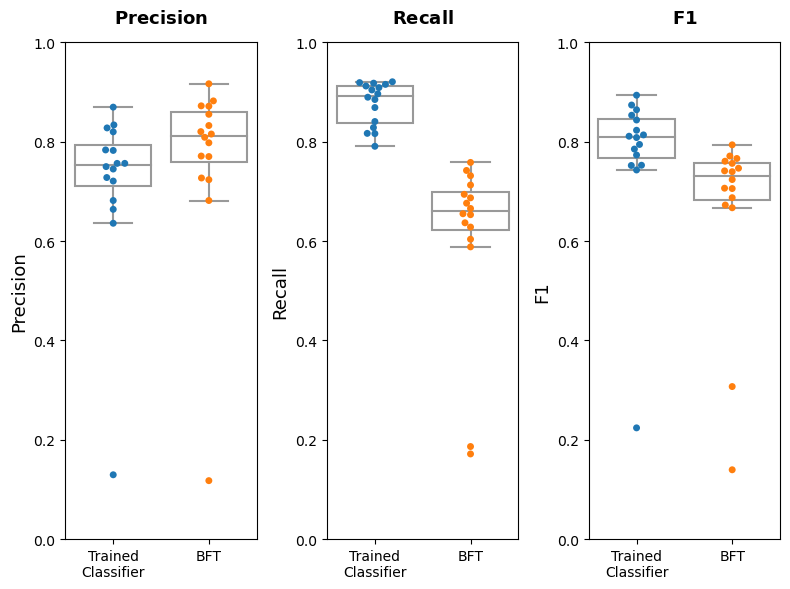

In [7]:
### GS VS BFT ###

fig,axes = plt.subplots(1,3,figsize=(8,6))
axes = axes.ravel()
results_df_long = pd.melt(results_df,id_vars=['fov'])

precision_order = [
    'model_precision',
    'bft_precision'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(precision_order)],
    x='variable',
    y='value',
    order=precision_order,
    color='white',
    showfliers=False,
    ax=axes[0]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(precision_order)],
    x='variable',
    y='value',
    order=precision_order,
    ax=axes[0]
)
recall_order = [
    'model_recall',
    'bft_recall'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(recall_order)],
    x='variable',
    y='value',
    order=recall_order,
    color='white',
    showfliers=False,
    ax=axes[1]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(recall_order)],
    x='variable',
    y='value',
    order=recall_order,
    ax=axes[1]
)

f1_order = [
    'model_f1',
    'bft_f1'
]

sns.boxplot(
    data=results_df_long.loc[results_df_long['variable'].isin(f1_order)],
    x='variable',
    y='value',
    order=f1_order,
    color='white',
    showfliers=False,
    ax=axes[2]
)

sns.swarmplot(
    data=results_df_long.loc[results_df_long['variable'].isin(f1_order)],
    x='variable',
    y='value',
    order=f1_order,
    ax=axes[2]
)

axes[0].set_title(r'$\mathbf{Precision}$', fontsize=13, pad=14)
axes[1].set_title(r'$\mathbf{Recall}$', fontsize=13, pad=14)
axes[2].set_title(r'$\mathbf{F1}$', fontsize=13, pad=14)

axes[0].set_ylabel('Precision', fontsize=13)
axes[1].set_ylabel('Recall', fontsize=13)
axes[2].set_ylabel('F1', fontsize=13)

for ax in axes:
    ax.set_xticks([0, 1])                                   # avoids the FixedFormatter warning
    ax.set_xticklabels(['Trained\nClassifier', 'BFT'])
    ax.set_xlabel('')                                       # kills the 'variable' label
    ax.set_ylim(0, 1)

fig.tight_layout()
fig.savefig(os.path.join(output_dir, 'testset_results_lm50gs_GS_BFT_only_final.svg'))

In [12]:
from scipy.stats import ttest_rel

# ================= shared functions =================
def p_to_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def compute_stats(df, methods, metrics, reference, test=ttest_rel):
    """Paired test of every method against the reference, for each metric."""
    df = df.sort_values('fov').reset_index(drop=True)
    rows = []
    for metric in metrics:
        for m in methods:
            if m == reference:
                continue
            stat, p = test(df[f'{m}_{metric}'], df[f'{reference}_{metric}'])
            rows.append({'test': metric, 'a': m, 'b': reference,
                         'type': f'{m} vs {reference}', 'stat': stat, 'p-value': p})
    stats_df = pd.DataFrame(rows)
    stats_df['stars'] = stats_df['p-value'].apply(p_to_stars)
    return stats_df

def add_significance(ax, x1, x2, y, h, text, fontsize=12, lw=0.8):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=lw, c='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=fontsize)

def annotate_axis(ax, df, methods, metric, stats_df, show_ns=True,
                  gap=0.04, step=0.07, h=0.015, ymin_zero=False):
    vals = df[[f'{m}_{metric}' for m in methods]].to_numpy()
    lo, hi = vals.min(), vals.max()
    rng = hi - lo
    sub = stats_df[stats_df['test'] == metric]
    if not show_ns:
        sub = sub[sub['stars'] != 'ns']
    # list comprehension instead of df.apply: apply() breaks when sub is empty (all 'ns' + show_ns=False)
    sub = sub.assign(span=[abs(methods.index(a) - methods.index(b))
                           for a, b in zip(sub['a'], sub['b'])])
    y = hi + gap * rng
    for _, row in sub.sort_values('span').iterrows():
        x1, x2 = sorted([methods.index(row['a']), methods.index(row['b'])])
        add_significance(ax, x1, x2, y, h * rng, row['stars'])
        y += step * rng
    bottom = min(0, lo) if ymin_zero else None
    ax.set_ylim(bottom, y + 0.02 * rng)

def plot_benchmark(df, methods, metrics, labels, titles, stats_df,
                   colors=None, show_ns=True, ymin_zero=False,
                   figsize=None, tick_fontsize=12):
    df = df.sort_values('fov').reset_index(drop=True)
    long = pd.melt(df, id_vars=['fov'])
    figsize = figsize or (4 * len(metrics), 6)
    fig, axes = plt.subplots(1, len(metrics), figsize=figsize, squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        order = [f'{m}_{metric}' for m in methods]
        sub = long[long['variable'].isin(order)]
        sns.boxplot(data=sub, x='variable', y='value', order=order,
                    color='white', showfliers=False, ax=ax)
        if colors:
            palette = {f'{m}_{metric}': colors[m] for m in methods}
            sns.swarmplot(data=sub, x='variable', y='value', order=order,
                          hue='variable', hue_order=order, palette=palette, ax=ax)
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        else:
            sns.swarmplot(data=sub, x='variable', y='value', order=order, ax=ax)

        annotate_axis(ax, df, methods, metric, stats_df,
                      show_ns=show_ns, ymin_zero=ymin_zero)
        title_tex = titles[metric].replace(' ', r'\ ')
        ax.set_title(rf'$\mathbf{{{title_tex}}}$', fontsize=13, pad=14)
        ax.set_ylabel(titles[metric], fontsize=13)
        ax.set_xlabel('')
        ax.set_xticks(range(len(methods)), labels=[labels[m] for m in methods],
                      fontsize=tick_fontsize)

    fig.tight_layout()
    return fig, axes

Undefined metrics (handled exactly as in cell 6):
  003_007 Cacna1a: 0 ground-truth spots -> recall set to 0 (sklearn default)
  003_008 Cacna1i: 0 ground-truth spots -> recall set to 0 (sklearn default)
                   count      mean       std       min       25%       50%  \
Slc1a2_precision    16.0  0.732294  0.178111  0.129032  0.735111  0.778212   
Slc1a2_recall       16.0  0.846813  0.100930  0.500000  0.824657  0.888249   
Slc1a2_f1           16.0  0.778047  0.161386  0.205128  0.780198  0.818064   
Cacna1i_precision   16.0  0.534353  0.362709  0.000000  0.111607  0.703373   
Cacna1i_recall      16.0  0.652481  0.359386  0.000000  0.571429  0.839420   
Cacna1i_f1          16.0  0.569369  0.363471  0.000000  0.162693  0.788206   
Cacna1a_precision   16.0  0.584801  0.277908  0.000000  0.555523  0.669093   
Cacna1a_recall      16.0  0.863287  0.257750  0.000000  0.922921  0.944699   
Cacna1a_f1          16.0  0.676297  0.289811  0.000000  0.702165  0.780029   

               

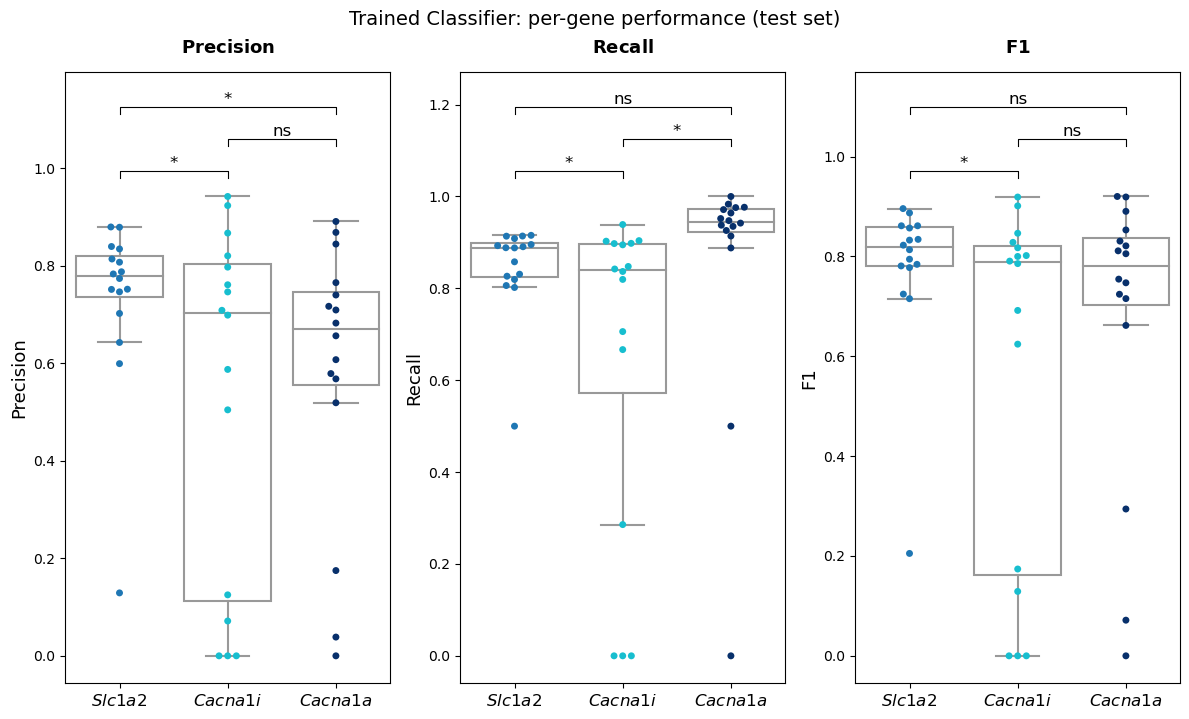

,test,a,b,type,stat,p-value,stars
0,precision,Slc1a2,Cacna1i,Slc1a2 vs Cacna1i,2.324249,0.034563,*
1,precision,Slc1a2,Cacna1a,Slc1a2 vs Cacna1a,2.160839,0.047292,*
2,precision,Cacna1i,Cacna1a,Cacna1i vs Cacna1a,-0.738983,0.471323,ns
3,recall,Slc1a2,Cacna1i,Slc1a2 vs Cacna1i,2.391579,0.030320,*
4,recall,Slc1a2,Cacna1a,Slc1a2 vs Cacna1a,-0.253358,0.803432,ns
5,recall,Cacna1i,Cacna1a,Cacna1i vs Cacna1a,-2.521797,0.023473,*
6,f1,Slc1a2,Cacna1i,Slc1a2 vs Cacna1i,2.519828,0.023564,*
7,f1,Slc1a2,Cacna1a,Slc1a2 vs Cacna1a,1.500326,0.154283,ns
8,f1,Cacna1i,Cacna1a,Cacna1i vs Cacna1a,-1.610898,0.128040,ns


In [22]:
### Per-gene F1 on the test set: Trained Classifier (one box per gene, one point per test FOV) ###
from itertools import combinations
import warnings
from sklearn.exceptions import UndefinedMetricWarning

def f1_or_nan(y_true, y_pred):
    """F1 = 2TP / (2TP + FP + FN). Returns NaN when the gene has no true and no
    predicted positives in this FOV, so it is left out instead of counted as 0."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = 2 * tp + fp + fn
    return np.nan if denom == 0 else 2 * tp / denom

def compute_stats_pairwise(df, groups, metrics, test=ttest_rel):
    """Paired test for every pair of groups (all-vs-all), same output format as compute_stats (cell 8)."""
    df = df.sort_values('fov').reset_index(drop=True)
    rows = []
    for metric in metrics:
        for a, b in combinations(groups, 2):
            stat, p = test(df[f'{a}_{metric}'], df[f'{b}_{metric}'])
            rows.append({'test': metric, 'a': a, 'b': b,
                         'type': f'{a} vs {b}', 'stat': stat, 'p-value': p})
    stats_df = pd.DataFrame(rows)
    stats_df['stars'] = stats_df['p-value'].apply(p_to_stars)
    return stats_df

# ---- per-gene precision / recall / F1 per test FOV (same predictions + sklearn defaults as cell 6) ----
rows = []
undefined = []
for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])

    row = {'fov': test_fov}
    for gene in GS_gene_list:
        g = Y_fov_subset.loc[Y_fov_subset['gene'] == gene]
        y_true, y_pred = g['Label'], g['pred']
        if y_true.sum() == 0:
            undefined.append(f'{test_fov} {gene}: 0 ground-truth spots -> recall set to 0 (sklearn default)')
        if y_pred.sum() == 0:
            undefined.append(f'{test_fov} {gene}: 0 predicted spots -> precision set to 0 (sklearn default)')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UndefinedMetricWarning)
            row[f'{gene}_precision'] = precision_score(y_true, y_pred, zero_division=0)
            row[f'{gene}_recall']    = recall_score(y_true, y_pred, zero_division=0)
            row[f'{gene}_f1']        = f1_score(y_true, y_pred, zero_division=0)
    rows.append(row)

per_gene_results_df = pd.DataFrame(rows)
per_gene_results_df.to_csv(os.path.join(output_dir, 'testset_per_gene_results_model_lm50gs.csv'), index=False)

if undefined:
    print('Undefined metrics (handled exactly as in cell 6):')
    print('\n'.join('  ' + u for u in undefined))
print(per_gene_results_df.describe().T)

# ---- stats: all pairwise paired t-tests between genes, for each metric ----
metrics_g = ['precision', 'recall', 'f1']
per_gene_stats_df = compute_stats_pairwise(per_gene_results_df, GS_gene_list, metrics_g)
per_gene_stats_df.to_csv(os.path.join(output_dir, 'testset_per_gene_results_model_stats_lm50gs.csv'), index=False)

# ---- plot: 1 x 3 panels (Precision, Recall, F1), 3 genes per panel ----
gene_colors = {'Slc1a2': '#1f77b4', 'Cacna1i': '#17becf', 'Cacna1a': '#08306b'}   # change as you like
gene_labels = {g: rf'$\it{{{g}}}$' for g in GS_gene_list}                           # italic gene names
titles_g    = {'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1'}

fig, axes = plot_benchmark(per_gene_results_df, GS_gene_list, metrics_g,
                           gene_labels, titles_g, per_gene_stats_df,
                           colors=gene_colors, figsize=(12, 7))
fig.suptitle('Trained Classifier: per-gene performance (test set)', fontsize=14, y=1.02)
fig.savefig(os.path.join(output_dir, 'testset_per_gene_results_model_lm50gs.svg'), bbox_inches='tight')
plt.show()

per_gene_stats_df

In [18]:
### Diagnostics: is the Slc1a2 vs Cacna1i difference real, or driven by low-count FOVs? ###
from scipy.stats import wilcoxon, ttest_1samp, spearmanr

# ---- 1. per-FOV TP/FP/FN and number of true positives per gene ----
rows = []
for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    for gene in GS_gene_list:
        g = Y_fov_subset.loc[Y_fov_subset['gene'] == gene]
        y, p = g['Label'].astype(int).to_numpy(), g['pred'].astype(int).to_numpy()
        tp, fp, fn = int(((y == 1) & (p == 1)).sum()), int(((y == 0) & (p == 1)).sum()), int(((y == 1) & (p == 0)).sum())
        rows.append({'fov': test_fov, 'gene': gene, 'n_spots': len(g), 'n_true_pos': int(y.sum()),
                     'tp': tp, 'fp': fp, 'fn': fn,
                     'f1': np.nan if (2*tp + fp + fn) == 0 else 2*tp / (2*tp + fp + fn)})
counts_df = pd.DataFrame(rows)

print('--- Per-FOV detail, sorted by F1 (look at n_true_pos in the low-F1 FOVs) ---')
for gene in ['Slc1a2', 'Cacna1i']:
    print(f'\n{gene}')
    print(counts_df.loc[counts_df['gene'] == gene].sort_values('f1')[['fov', 'n_spots', 'n_true_pos', 'tp', 'fp', 'fn', 'f1']].to_string(index=False))
    sub = counts_df.loc[counts_df['gene'] == gene].dropna(subset=['f1'])
    rho, p_rho = spearmanr(sub['n_true_pos'], sub['f1'])
    print(f'Spearman(F1, n_true_pos) for {gene}: rho = {rho:.2f}, p = {p_rho:.3g}')

# ---- 2. pooled (micro) F1 per gene with FOV-bootstrap 95% CI ----
def pooled_f1(df):
    tp, fp, fn = df['tp'].sum(), df['fp'].sum(), df['fn'].sum()
    return 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) > 0 else np.nan

rng = np.random.default_rng(0)
n_boot = 5000
fovs = np.array(testing_fovs)
print('\n--- Pooled F1 (all test spots), 95% bootstrap CI over FOVs ---')
boot_store = {}
for gene in GS_gene_list:
    gdf = counts_df.loc[counts_df['gene'] == gene].set_index('fov')
    boots = [pooled_f1(gdf.loc[rng.choice(fovs, size=len(fovs), replace=True)]) for _ in range(n_boot)]
    boot_store[gene] = np.array(boots)
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    print(f'{gene:8s}: pooled F1 = {pooled_f1(gdf):.3f}  [95% CI {lo:.3f}-{hi:.3f}]')

# paired bootstrap of the difference (same resampled FOVs for both genes)
s = counts_df.loc[counts_df['gene'] == 'Slc1a2'].set_index('fov')
c = counts_df.loc[counts_df['gene'] == 'Cacna1i'].set_index('fov')
diffs = []
for _ in range(n_boot):
    idx = rng.choice(fovs, size=len(fovs), replace=True)
    diffs.append(pooled_f1(s.loc[idx]) - pooled_f1(c.loc[idx]))
lo, hi = np.nanpercentile(diffs, [2.5, 97.5])
print(f'Pooled F1 difference Slc1a2 - Cacna1i: {pooled_f1(s) - pooled_f1(c):.3f}  [95% CI {lo:.3f} to {hi:.3f}]')

# ---- 3. Wilcoxon signed-rank (non-parametric, paired) with Holm correction across the 3 pairs ----
wide = counts_df.pivot(index='fov', columns='gene', values='f1')[GS_gene_list].dropna()
pairs = [('Slc1a2', 'Cacna1i'), ('Slc1a2', 'Cacna1a'), ('Cacna1i', 'Cacna1a')]
res = []
for a, b in pairs:
    t_p = ttest_rel(wide[a], wide[b]).pvalue
    w_p = wilcoxon(wide[a], wide[b]).pvalue
    res.append({'pair': f'{a} vs {b}', 'ttest_p': t_p, 'wilcoxon_p': w_p,
                'median_diff': np.median(wide[a] - wide[b])})
res = pd.DataFrame(res)

def holm(pvals):
    pvals = np.asarray(pvals); m = len(pvals); order = np.argsort(pvals)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(running, 1)
    return adj

res['ttest_p_holm'] = holm(res['ttest_p'])
res['wilcoxon_p_holm'] = holm(res['wilcoxon_p'])
print('\n--- Paired tests across the 3 gene pairs ---')
print(res.to_string(index=False))

# ---- 4. Equivalence test (paired TOST) for Slc1a2 vs Cacna1i ----
margin = 0.10   # equivalence margin in F1 units -- choose and justify BEFORE looking at the result
d = (wide['Slc1a2'] - wide['Cacna1i']).to_numpy()
p_lower = ttest_1samp(d, -margin, alternative='greater').pvalue
p_upper = ttest_1samp(d,  margin, alternative='less').pvalue
print(f'\n--- TOST, margin +/-{margin} ---')
print(f'mean diff = {d.mean():.3f}; p_lower = {p_lower:.3g}, p_upper = {p_upper:.3g}; '
      f'TOST p = {max(p_lower, p_upper):.3g} -> {"equivalent" if max(p_lower, p_upper) < 0.05 else "equivalence NOT shown"}')

--- Per-FOV detail, sorted by F1 (look at n_true_pos in the low-F1 FOVs) ---

Slc1a2
    fov  n_spots  n_true_pos   tp  fp  fn       f1
003_008      114           8    4  27   4 0.205128
002_007      905         402  357 239  45 0.715431
002_006      964         532  442 246  90 0.724590
001_008     1576         985  794 263 191 0.777669
003_006     1211         714  585 199 129 0.781041
001_006      929         493  438 186  55 0.784244
003_007      405         217  174  47  43 0.794521
002_008     1044         689  591 173  98 0.813489
001_007     1561         896  814 269  82 0.822638
001_009     1714        1256 1038 199 218 0.832732
003_009     1151         747  667 185  80 0.834271
000_009     2105        1446 1321 316 125 0.856958
002_009     1706        1124 1001 199 123 0.861446
000_006     1380         934  855 196  79 0.861461
000_008     1867        1463 1310 180 153 0.887233
000_007     1548        1196 1093 151 103 0.895902
Spearman(F1, n_true_pos) for Slc1a2: rho = 0.78,

<user_home>\AppData\Local\miniforge3\envs\GS_JZ_new\lib\site-packages\scipy\stats\_morestats.py:3337: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "


In [19]:
### Sensitivity analysis: FOVs with >= min_true ground-truth spots for both genes ###
min_true = 10
ntp = counts_df.pivot(index='fov', columns='gene', values='n_true_pos')
f1w = counts_df.pivot(index='fov', columns='gene', values='f1')
keep = ntp.index[(ntp['Slc1a2'] >= min_true) & (ntp['Cacna1i'] >= min_true)]
a, b = f1w.loc[keep, 'Slc1a2'], f1w.loc[keep, 'Cacna1i']
d = (a - b).to_numpy()
print(f'FOVs kept: {len(keep)} / {len(f1w)}  -> {list(keep)}')
print(f'median F1: Slc1a2 {a.median():.3f}, Cacna1i {b.median():.3f}; mean diff {d.mean():.3f}')
print(f'paired t-test p = {ttest_rel(a, b).pvalue:.3g}; Wilcoxon p = {wilcoxon(a, b).pvalue:.3g}')
for margin in [0.05, 0.10]:
    p_tost = max(ttest_1samp(d, -margin, alternative='greater').pvalue,
                 ttest_1samp(d,  margin, alternative='less').pvalue)
    print(f'TOST +/-{margin}: p = {p_tost:.3g} -> {"equivalent" if p_tost < 0.05 else "not shown"}')

FOVs kept: 11 / 16  -> ['000_007', '000_008', '000_009', '001_006', '001_007', '001_008', '001_009', '002_006', '002_007', '002_008', '003_009']
median F1: Slc1a2 0.823, Cacna1i 0.802; mean diff 0.013
paired t-test p = 0.447; Wilcoxon p = 0.638
TOST +/-0.05: p = 0.02 -> equivalent
TOST +/-0.1: p = 0.000129 -> equivalent


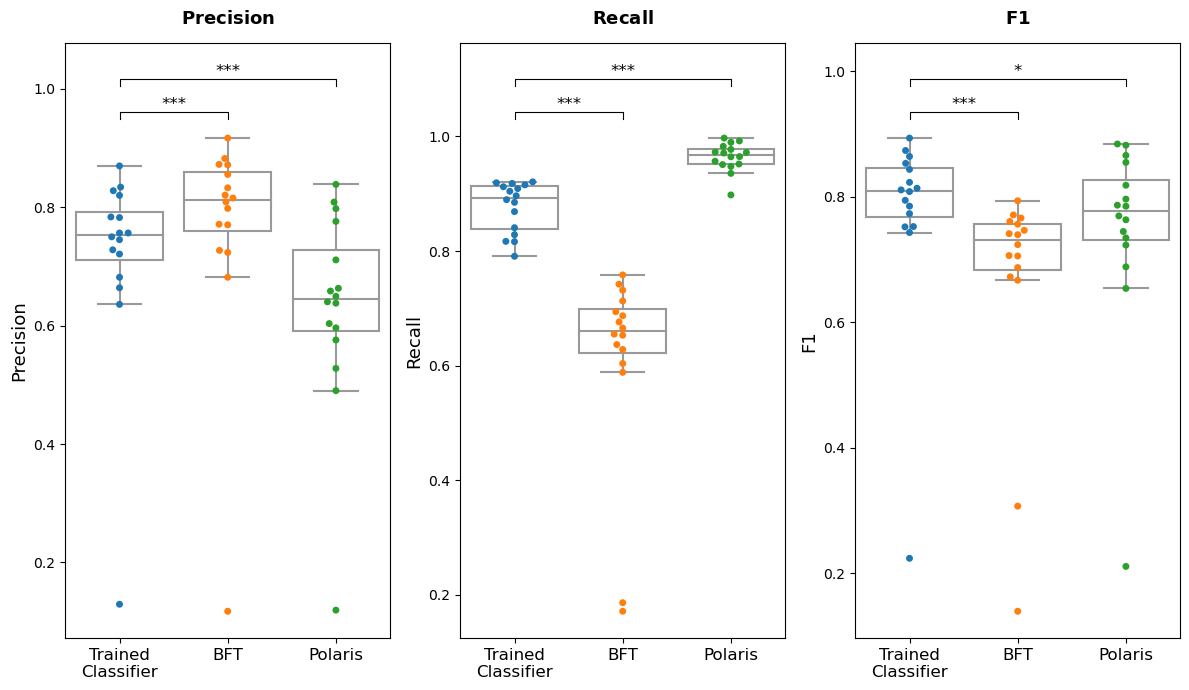

In [9]:
### Fig 2d, 2e, 2f ###
colors  = {'model': '#1f77b4', 'bft': '#ff7f0e', 'polaris': '#2ca02c',
           'merlin': '#d62728', 'starfish': '#9467bd'}

reference = 'model'
methods = ['model', 'bft', 'polaris']
labels  = {'model': 'Trained\nClassifier', 'bft': 'BFT',
           'polaris': 'Polaris'}
titles  = {'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1', 'auroc': 'AUROC'}

stats_results_df = compute_stats(results_df, methods,
                                 ['precision', 'recall', 'f1', 'auroc'], reference)
fig, axes = plot_benchmark(results_df, methods, ['precision', 'recall', 'f1'],
                           labels, titles, stats_results_df, colors=colors, figsize=(12, 7))
fig.savefig(os.path.join(output_dir, 'testset_results_lm50gs_benchmark_p_edge_crio.svg'))

In [10]:
results_df.describe()

,model_precision,model_recall,model_f1,model_auroc,bft_precision,bft_recall,bft_f1,bft_auroc,polaris_precision,polaris_recall,polaris_f1,polaris_auroc
count,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000
mean,0.717864,0.877067,0.775728,0.789325,0.766603,0.611994,0.667927,0.759648,0.630886,0.964099,0.747804,0.645748
std,0.169233,0.043902,0.153891,0.054966,0.184438,0.175623,0.179874,0.049395,0.169130,0.024622,0.158011,0.046935
min,0.129464,0.790909,0.223938,0.658629,0.117647,0.171429,0.139535,0.649492,0.119565,0.897959,0.211031,0.559085
25%,0.711110,0.837735,0.768187,0.753867,0.759453,0.622169,0.683717,0.732194,0.591169,0.951665,0.731821,0.612848
50%,0.753238,0.893125,0.809853,0.793400,0.812289,0.660389,0.731857,0.761119,0.644925,0.967972,0.777439,0.659918
75%,0.792680,0.913075,0.846253,0.831112,0.859414,0.698836,0.757558,0.793128,0.727288,0.978708,0.827706,0.670335
max,0.869745,0.920804,0.893768,0.862436,0.916750,0.758418,0.793833,0.825260,0.838498,0.997181,0.884377,0.739510


In [11]:
stats_results_df

,test,a,b,type,stat,p-value,stars
0,precision,bft,model,bft vs model,6.881859,5.218124e-06,***
1,precision,polaris,model,polaris vs model,-4.761586,2.522086e-04,***
2,recall,bft,model,bft vs model,-6.845827,5.545298e-06,***
3,recall,polaris,model,polaris vs model,6.736048,6.681320e-06,***
4,f1,bft,model,bft vs model,-4.251103,6.971779e-04,***
5,f1,polaris,model,polaris vs model,-2.697966,1.652604e-02,*
6,auroc,bft,model,bft vs model,-3.263225,5.239368e-03,**
7,auroc,polaris,model,polaris vs model,-12.110375,3.813898e-09,***


In [12]:
compute_stats(results_df, methods,
              ['precision', 'recall', 'f1', 'auroc'], 'bft')

,test,a,b,type,stat,p-value,stars
0,precision,model,bft,model vs bft,-6.881859,5.218124e-06,***
1,precision,polaris,bft,polaris vs bft,-6.101129,2.027926e-05,***
2,recall,model,bft,model vs bft,6.845827,5.545298e-06,***
3,recall,polaris,bft,polaris vs bft,8.493962,4.085819e-07,***
4,f1,model,bft,model vs bft,4.251103,6.971779e-04,***
5,f1,polaris,bft,polaris vs bft,3.750292,1.929797e-03,**
6,auroc,model,bft,model vs bft,3.263225,5.239368e-03,**
7,auroc,polaris,bft,polaris vs bft,-15.270737,1.507648e-10,***


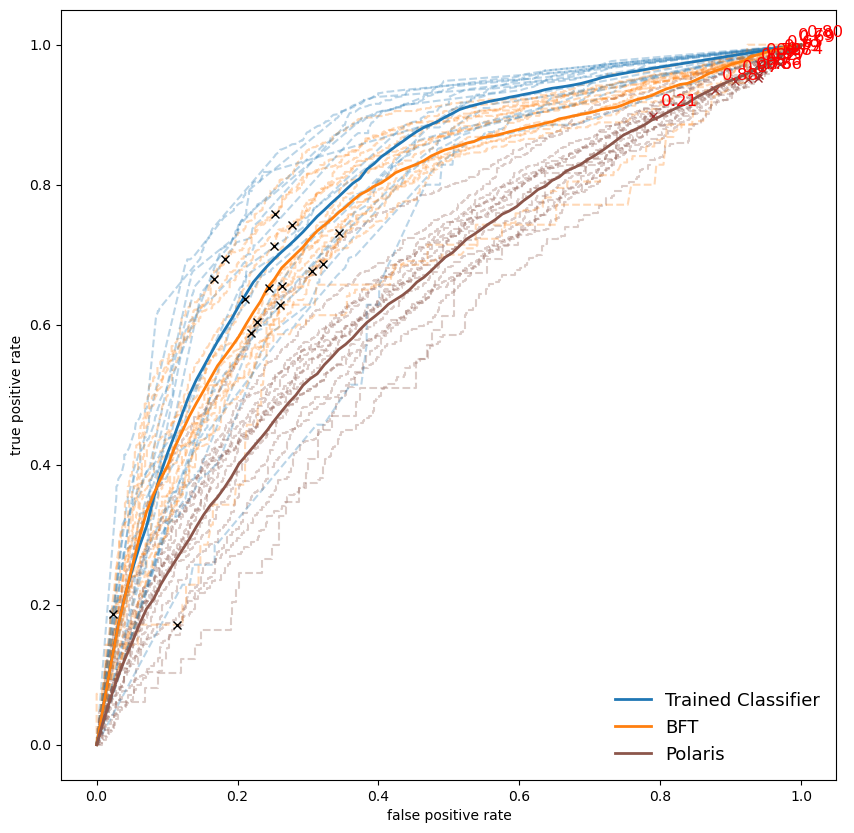

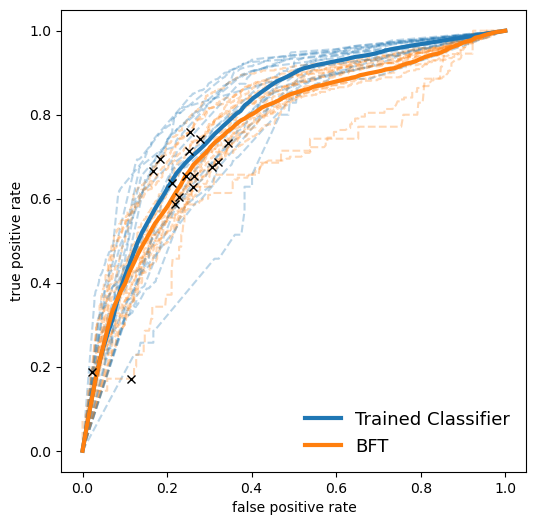

In [13]:
# --- storage ---
tprs_model, fprs_model, aucs_model = [], [], []
tprs_bft,   fprs_bft,   aucs_bft   = [], [], []
tprs_polaris, fprs_polaris, aucs_polaris = [], [], []
mean_fpr = np.linspace(0, 1, 100)

# --- two figures: fig1 = all methods, fig2 = GS vs BFT only ---
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 10))
fig2, ax2 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(testing_fovs):
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(
            fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(
        fov_subset_transformed[features_to_use])[:, 1]

    polaris_sub = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov].copy()
    polaris_sub['pred'] = (polaris_sub['probability'] >= 0.95).astype(int)


    # --- restrict to GS genes once ---
    m = Y_fov_subset['gene'].isin(GS_gene_list)
    p = polaris_sub['gene'].isin(GS_gene_list)

    # --- ROC curves (no stray figures) ---
    fpr_model, tpr_model, _ = roc_curve(Y_fov_subset.loc[m, 'Label'],
                                        Y_fov_subset.loc[m, 'pred_score'])
    auc_model = roc_auc_score(Y_fov_subset.loc[m, 'Label'],
                              Y_fov_subset.loc[m, 'pred_score'])

    fpr_bft, tpr_bft, _ = roc_curve(Y_fov_subset.loc[m, 'Label'],
                                    1 - Y_fov_subset.loc[m, 'bfs'])
    auc_bft = roc_auc_score(Y_fov_subset.loc[m, 'Label'],
                            1 - Y_fov_subset.loc[m, 'bfs'])

    fpr_pol, tpr_pol, _ = roc_curve(polaris_sub.loc[p, 'Label'],
                                    polaris_sub.loc[p, 'probability'])
    auc_pol = roc_auc_score(polaris_sub.loc[p, 'Label'],
                            polaris_sub.loc[p, 'probability'])

    # --- interpolate + store ---
    for fpr_, tpr_, auc_, tl, fl, al in [
        (fpr_model, tpr_model, auc_model, tprs_model, fprs_model, aucs_model),
        (fpr_bft,   tpr_bft,   auc_bft,   tprs_bft,   fprs_bft,   aucs_bft),
        (fpr_pol,   tpr_pol,   auc_pol,   tprs_polaris, fprs_polaris, aucs_polaris),
    ]:
        it = np.interp(mean_fpr, fpr_, tpr_); it[0] = 0
        ifp = np.interp(mean_fpr, tpr_, fpr_); ifp[0] = 0
        tl.append(it); fl.append(ifp); al.append(auc_)

    # --- per-FOV faint curves ---
    # fig1: all four
    ax1.plot(fpr_model, tpr_model, ls='dashed', alpha=0.3, color='tab:blue')
    ax1.plot(fpr_bft,   tpr_bft,   ls='dashed', alpha=0.3, color='tab:orange')
    ax1.plot(fpr_pol,   tpr_pol,   ls='dashed', alpha=0.3, color='tab:brown')
    # fig2: GS + BFT only
    ax2.plot(fpr_model, tpr_model, ls='dashed', alpha=0.3, color='tab:blue')
    ax2.plot(fpr_bft,   tpr_bft,   ls='dashed', alpha=0.3, color='tab:orange')

    # --- BFT operating point (goes on BOTH figures) ---
    TP = ((Y_fov_subset['Label'] == 1) & (Y_fov_subset['bft_result'] == 1) & m).sum()
    FP = ((Y_fov_subset['Label'] == 0) & (Y_fov_subset['bft_result'] == 1) & m).sum()
    FN = ((Y_fov_subset['Label'] == 1) & (Y_fov_subset['bft_result'] == 0) & m).sum()
    TN = ((Y_fov_subset['Label'] == 0) & (Y_fov_subset['bft_result'] == 0) & m).sum()
    misid_fpr = FP / (FP + TN)
    misid_tpr = TP / (TP + FN)
    ax1.plot(misid_fpr, misid_tpr, 'x', color='black', zorder=10)
    ax2.plot(misid_fpr, misid_tpr, 'x', color='black', zorder=10)

    # --- Polaris @0.95 operating point (fig1 only) ---
    TP_p = ((polaris_sub['Label'] == 1) & (polaris_sub['pred'] == 1) & p).sum()
    FP_p = ((polaris_sub['Label'] == 0) & (polaris_sub['pred'] == 1) & p).sum()
    FN_p = ((polaris_sub['Label'] == 1) & (polaris_sub['pred'] == 0) & p).sum()
    TN_p = ((polaris_sub['Label'] == 0) & (polaris_sub['pred'] == 0) & p).sum()
    ax1.plot(FP_p / (FP_p + TN_p), TP_p / (TP_p + FN_p), 'x', color='brown')
    pol_f1 = f1_score(polaris_sub.loc[p, 'Label'], polaris_sub.loc[p, 'pred'])
    ax1.text(FP_p / (FP_p + TN_p) + 0.01, TP_p / (TP_p + FN_p) + 0.01,
             f'{pol_f1:.2f}', color='red', fontsize=12, ha='left', va='bottom')


# --- mean curves ---
mean_tpr_model   = np.mean(tprs_model,   axis=0); mean_tpr_model[-1]   = 1
mean_tpr_bft     = np.mean(tprs_bft,     axis=0); mean_tpr_bft[-1]     = 1
mean_tpr_polaris = np.mean(tprs_polaris, axis=0); mean_tpr_polaris[-1] = 1

ax1.plot(mean_fpr, mean_tpr_model,   color='tab:blue',   lw=2, label='Trained Classifier')
ax1.plot(mean_fpr, mean_tpr_bft,     color='tab:orange', lw=2, label='BFT')
ax1.plot(mean_fpr, mean_tpr_polaris, color='tab:brown',  lw=2, label='Polaris')

ax2.plot(mean_fpr, mean_tpr_model, color='tab:blue',   lw=3, label='Trained Classifier')
ax2.plot(mean_fpr, mean_tpr_bft,   color='tab:orange', lw=3, label='BFT')

for ax in (ax1, ax2):
    ax.legend(loc='lower right', fontsize=13, markerscale=1.5, frameon=False)
    ax.set_xlabel('false positive rate')
    ax.set_ylabel('true positive rate')

fig1.savefig(os.path.join(output_dir, 'ROC_withmisid_mbrain_benchmark.svg'))
fig2.savefig(os.path.join(output_dir, 'ROC_mbrain_withmisid_GS_BFT_only.svg'))

In [14]:
from sklearn.metrics import auc

auc_mean_model   = auc(mean_fpr, mean_tpr_model)
auc_mean_bft     = auc(mean_fpr, mean_tpr_bft)
auc_mean_polaris = auc(mean_fpr, mean_tpr_polaris)

print(f'AUC mean for Trained Classifier: {auc_mean_model:.3f}')
print(f'AUC mean for BFT: {auc_mean_bft:.3f}')
print(f'AUC mean for Polaris: {auc_mean_polaris:.3f}')

AUC mean for Trained Classifier: 0.789
AUC mean for BFT: 0.760
AUC mean for Polaris: 0.646


In [15]:
# merfish by fov
model_fpkm_result = []
model_counts_result = []
model_misid_result = []

bft_fpkm_result = []
bft_counts_result = []
bft_misid_result = []

all_model_callouts = []
all_bft_callouts = []

merfish_data['bft_result'] = 0
merfish_data.loc[merfish_data['bfs'] <= bft, 'bft_result'] = 1
for merfish_fov in merfish_data['fov'].unique():
    merfish_subset = merfish_data[features_to_use + ['bfs', 'bft_result', 'gene']].loc[merfish_data['fov'] == merfish_fov]
    merfish_subset_transformed = cm.transform(merfish_subset[features_to_use])
    for col in merfish_subset_transformed.columns:
        merfish_subset_transformed[col] = merfish_subset_transformed[col].fillna(merfish_subset_transformed[col].max())
    merfish_subset_transformed['pred'] = RF.predict(merfish_subset_transformed[features_to_use])
    model_callouts = list(merfish_subset['gene'].loc[merfish_subset_transformed['pred']==1])
    model_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, model_callouts)
    model_fpkm_val, _ = calcLogCorrelation(np.array(model_counts_arr), np.array(fpkm_list))
    model_mis_id_rate = calc_misid(model_counts_arr, model_callouts)
    
    bft_callouts = list(merfish_subset['gene'].loc[merfish_subset['bft_result']==1])
    bft_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, bft_callouts)
    bft_fpkm_val, _ = calcLogCorrelation(np.array(bft_counts_arr), np.array(fpkm_list))
    bft_mis_id_rate = calc_misid(bft_counts_arr, bft_callouts)
    
    model_fpkm_result.append(model_fpkm_val)
    model_counts_result.append(np.sum(model_counts_arr))
    model_misid_result.append(model_mis_id_rate)
    
    bft_fpkm_result.append(bft_fpkm_val)
    bft_counts_result.append(np.sum(bft_counts_arr))
    bft_misid_result.append(bft_mis_id_rate)

    all_model_callouts.extend(model_callouts)
    all_bft_callouts.extend(bft_callouts)

In [16]:
# ---- per-spot predictions for the spot-assignment script ----
merfish_out = merfish_data.copy()
merfish_out['bft_result'] = (merfish_out['bfs'] <= bft).astype(int)
merfish_out['pred'] = 0
merfish_out['pred_score'] = np.nan

for merfish_fov in merfish_out['fov'].unique():
    idx = merfish_out.index[merfish_out['fov'] == merfish_fov]
    X = cm.transform(merfish_out.loc[idx, features_to_use])
    for col in X.columns:                          # same per-FOV NaN fill as cell 15
        X[col] = X[col].fillna(X[col].max())
    merfish_out.loc[idx, 'pred'] = RF.predict(X[features_to_use])
    merfish_out.loc[idx, 'pred_score'] = RF.predict_proba(X[features_to_use])[:, 1]

# sanity checks: columns the script needs, and totals match the benchmark
missing = {'fov', 'x', 'y', 'gene', 'pred', 'bft_result', 'bfs'} - set(merfish_out.columns)
assert not missing, f'missing columns for spot assignment: {missing}'
print('GS  spots:', merfish_out['pred'].sum(),       '| cell 15 total:', sum(model_counts_result))
print('BFT spots:', merfish_out['bft_result'].sum(), '| cell 15 total:', sum(bft_counts_result))
print('fov examples:', merfish_out['fov'].unique()[:3])

out_dir = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/GS_model_result')
os.makedirs(out_dir, exist_ok=True)
merfish_out.to_csv(os.path.join(out_dir, 'merfish_full_data_GS_pred_output_p_crop_edge.csv'), index=False)

GS  spots: 671431 | cell 15 total: 671431
BFT spots: 296620 | cell 15 total: 296620
fov examples: ['007_006' '004_009' '003_000']


In [17]:
# load process data 
polaris_fpkm_result = []
polaris_counts_result = []
polaris_fov = []
all_polaris_callouts = []
folder = Path(polaris_main)
for file in folder.glob('*Polaris_prediction.csv'):
    file_breaks = file.name.split('_')
    fov = '_'.join(file_breaks[:2]) # adapted for triton file naming
    print(fov)
    polaris_fov.append(fov)
    df_polaris_sub = pd.read_csv(file)

    ### keep only probability >= 0.95
    df_polaris_sub = df_polaris_sub[df_polaris_sub['probability'] >= 0.95]
    polaris_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_polaris_sub['predicted_name'].tolist())
    polaris_fpkm_val, _ = calcLogCorrelation(np.array(polaris_counts_arr), np.array(fpkm_list))
    polaris_fpkm_result.append(polaris_fpkm_val)
    polaris_counts_result.append(np.sum(polaris_counts_arr))
    all_polaris_callouts.extend(df_polaris_sub['predicted_name'].tolist())
### format polaris output
# glob() does not return files in numeric FOV order (e.g. 0, 1, 10, 11, ...), so sort by fov
# before the columns are placed next to the other methods -- otherwise the paired t-tests pair the wrong FOVs
polaris_df_result = pd.DataFrame({'fov':polaris_fov, 'polaris_fpkm': polaris_fpkm_result,
                                  'polaris_count': polaris_counts_result}).sort_values('fov').reset_index(drop=True)

000_004
000_005
000_006
000_007
000_008
000_009
001_001
001_002
001_003
001_004
001_005
001_006
001_007
001_008
001_009
002_000
002_001
002_002
002_003
002_005
002_006
002_007
002_008
002_009
003_000
003_001
003_002
003_003
003_005
003_006
003_007
003_008
003_009
004_000
004_001
004_002
004_003
004_004
004_005
004_007
004_008
004_009
005_000
005_001
005_003
005_004
005_005
005_007
005_008
005_009
006_000
006_001
006_002
006_003
006_004
006_005
006_006
006_007
006_008
006_009
007_000
007_001
007_002
007_003
007_004
007_006
007_007
007_008
008_001
008_002
008_003
008_005
008_006
008_007
008_008
008_009
009_000
009_001
009_002
009_003
009_004
009_005
009_006
009_007
009_008
009_009


In [18]:
# this is matching starfish global normalization (for scale factor computation) to 99.9 percentile & 57 median in GS 
starfish_fpkm_result = []
starfish_counts_result = []
df_starfish = pd.read_csv(os.path.join(main_dir, 'Data/benchmarking/starfish/brain/starfish_result/lm50GS_brain_starfish_multifov.csv'))
for i, sub_fov in enumerate(df_starfish['fov'].unique()):
    df_starfish_sub = df_starfish[df_starfish['fov'] == sub_fov]
    starfish_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_starfish_sub['target'].tolist())
    starfish_fpkm_val, _ = calcLogCorrelation(np.array(starfish_counts_arr), np.array(fpkm_list))
    starfish_fpkm_result.append(starfish_fpkm_val)
    starfish_counts_result.append(np.sum(starfish_counts_arr))

In [19]:
merfish_results_df = pd.DataFrame({'fov':[i for i in range(nfovs)], 
                                   'model_fpkm': model_fpkm_result, 'model_counts':model_counts_result, 'model_misid': model_misid_result,
                                   'bft_fpkm': bft_fpkm_result, 'bft_counts': bft_counts_result, 'bft_misid': bft_misid_result,
                                   'starfish_fpkm': starfish_fpkm_result, 'starfish_counts': starfish_counts_result,
                                   'polaris_fpkm': polaris_df_result['polaris_fpkm'].tolist(), 'polaris_counts': polaris_df_result['polaris_count'].tolist()
                                   })
merfish_results_df.to_csv(os.path.join(output_dir, 'full_benchmarking_merfish_results_LM50GS_p_crop_edge.csv'))
merfish_results_df_long = pd.melt(merfish_results_df,id_vars=['fov'])

<user_home>\AppData\Local\miniforge3\envs\GS_JZ_new\lib\site-packages\seaborn\categorical.py:1296: UserWarning: 9.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


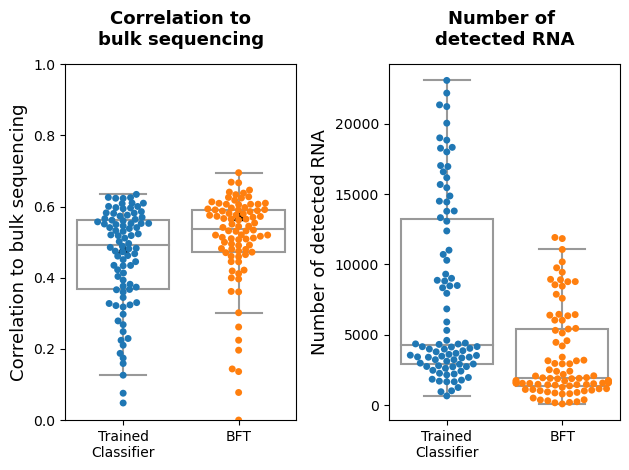

In [20]:
# FPKM, counts on all genes GS VS BFT only
fig,axes = plt.subplots(1,2)
axes = axes.ravel()
merfish_results_df_long = pd.melt(merfish_results_df,id_vars=['fov'])

sns.boxplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_fpkm','bft_fpkm'])], x = 'variable',y='value', color='white',showfliers=False,ax=axes[0])
sns.swarmplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_fpkm','bft_fpkm'])], x = 'variable',y='value',ax=axes[0])
axes[0].plot([0,1], [model_fpkm_val,bft_fpkm_val],'^',color='black',markersize=7)

sns.boxplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_counts','bft_counts'])], x = 'variable',y='value', color='white',showfliers=False,ax=axes[1])
sns.swarmplot(data=merfish_results_df_long.loc[merfish_results_df_long['variable'].isin(['model_counts','bft_counts'])], x = 'variable',y='value',ax=axes[1])

axes[0].set_ylim(0,1)

axes[0].set_title('fpkm')
axes[1].set_title('counts')

for ax in axes:
    ax.set_xticks([0, 1])                                   # avoids the FixedFormatter warning
    ax.set_xticklabels(['Trained\nClassifier', 'BFT'])
    ax.set_xlabel('')                                       # kills the 'variable' label

axes[0].set_title('Correlation to\nbulk sequencing', fontsize=13, fontweight='bold', pad=14)
axes[1].set_title('Number of \ndetected RNA', fontsize=13, fontweight='bold', pad=14)
axes[0].set_ylabel('Correlation to bulk sequencing', fontsize=13)
axes[1].set_ylabel('Number of detected RNA', fontsize=13)

fig.tight_layout()
fig.savefig(os.path.join(output_dir, 'merfish_results_LM50GS_withwhole_GS_BFT_only.svg'))

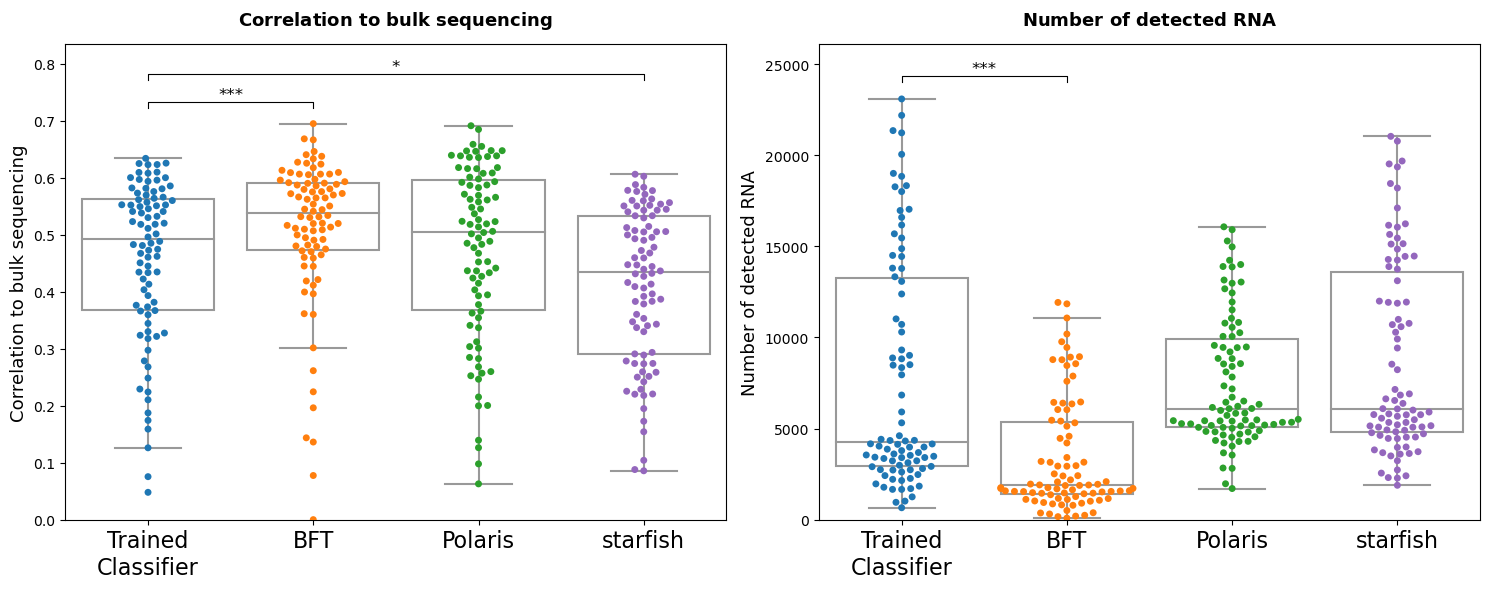

In [21]:
# FPKM, counts on all genes
methods_all = ['model', 'bft', 'polaris', 'starfish']
labels_all  = {**labels, 'starfish': 'starfish'}
titles_cnt  = {'fpkm': 'Correlation to bulk sequencing', 'counts': 'Number of detected RNA'}

count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(15, 6), tick_fontsize=16)
fig.savefig(os.path.join(output_dir, 'full_benchmarking_merfish_results_LM50GS_withwhole_p_crop_edge.svg'))

In [22]:
merfish_results_df.describe()

,fov,model_fpkm,model_counts,model_misid,bft_fpkm,bft_counts,bft_misid,starfish_fpkm,starfish_counts,polaris_fpkm,polaris_counts
count,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000
mean,42.500000,0.455925,7807.337209,0.395573,0.507709,3449.069767,0.185762,0.410492,8766.325581,0.471500,7560.395349
std,24.969982,0.141654,6375.724739,0.212312,0.133085,3144.244399,0.266164,0.135622,5307.457321,0.153607,3545.743822
min,0.000000,0.048010,655.000000,0.188522,0.000059,87.000000,0.029363,0.085837,1887.000000,0.062860,1709.000000
25%,21.250000,0.368711,2939.500000,0.254899,0.472746,1382.250000,0.061399,0.291670,4785.250000,0.368888,5085.000000
50%,42.500000,0.492400,4240.500000,0.329295,0.537666,1905.000000,0.109620,0.434532,6084.500000,0.505094,6095.500000
75%,63.750000,0.563559,13264.500000,0.448107,0.591403,5386.500000,0.202910,0.532530,13588.250000,0.596927,9929.750000
max,85.000000,0.634261,23085.000000,1.433005,0.695195,11920.000000,1.915493,0.606391,21033.000000,0.691525,16069.000000


In [23]:
count_results_df

,test,a,b,type,stat,p-value,stars
0,fpkm,bft,model,bft vs model,7.573191,4.059184e-11,***
1,fpkm,polaris,model,polaris vs model,0.653210,5.153841e-01,ns
2,fpkm,starfish,model,starfish vs model,-2.048424,4.360389e-02,*
3,counts,bft,model,bft vs model,-11.345434,1.058761e-18,***
4,counts,polaris,model,polaris vs model,-0.306248,7.601648e-01,ns
5,counts,starfish,model,starfish vs model,1.032124,3.049416e-01,ns


,test,a,b,type,stat,p-value,stars
0,fpkm,model,bft,model vs bft,-7.573191,4.059184e-11,***
1,fpkm,polaris,bft,polaris vs bft,-1.619104,1.091295e-01,ns
2,fpkm,starfish,bft,starfish vs bft,-4.649851,1.206646e-05,***
3,counts,model,bft,model vs bft,11.345434,1.058761e-18,***
4,counts,polaris,bft,polaris vs bft,7.808204,1.374587e-11,***
5,counts,starfish,bft,starfish vs bft,7.737905,1.901355e-11,***


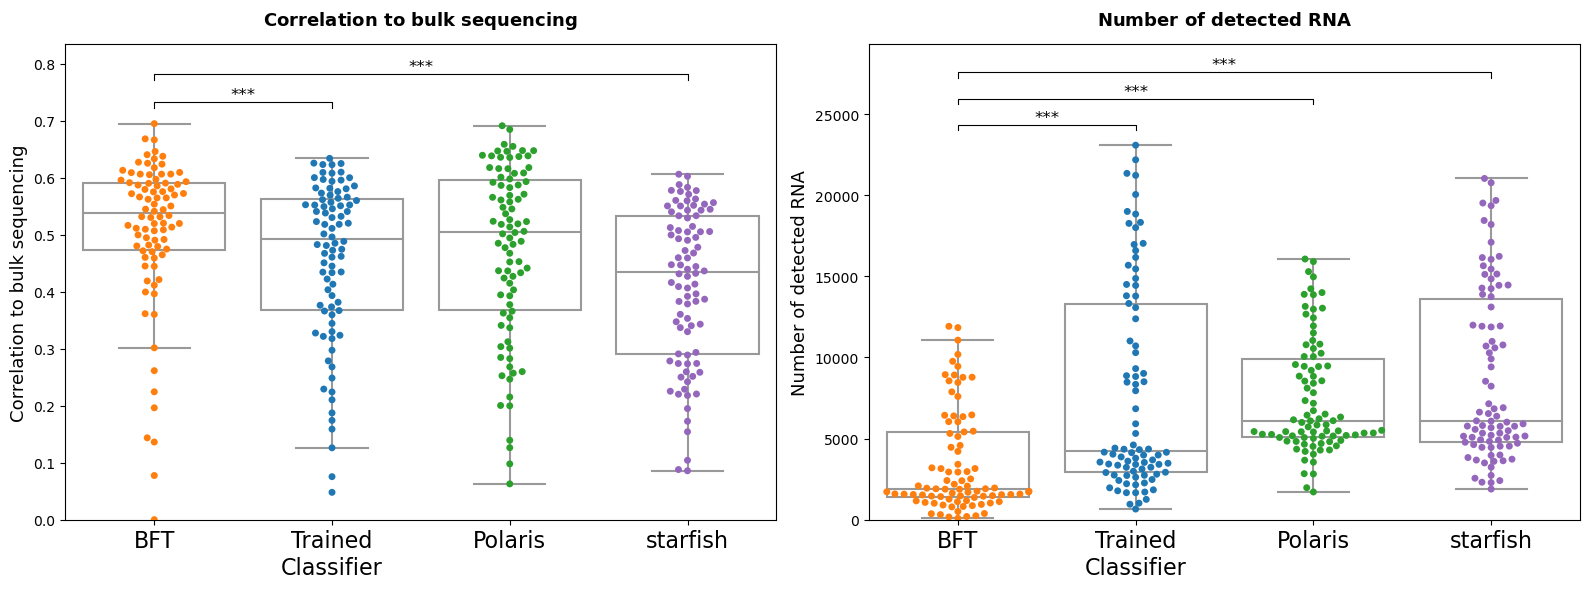

In [24]:
methods_all = ['bft', 'model', 'polaris', 'starfish']   # BFT at x=0, classifier at x=1

reference_bft = 'bft'
count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference_bft)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(16, 6), tick_fontsize=16)
fig.savefig(os.path.join(output_dir, 'full_benchmarking_merfish_results_LM50GS_ref_BFT_p_cropedge.svg'))
count_results_df

In [25]:
merfish_results_df.sum()

fov                  3655.000000
model_fpkm             39.209531
model_counts       671431.000000
model_misid            34.019259
bft_fpkm               43.662994
bft_counts         296620.000000
bft_misid              15.975535
starfish_fpkm          35.302303
starfish_counts    753904.000000
polaris_fpkm           40.549041
polaris_counts     650194.000000
dtype: float64

In [32]:
merfish_results_df.sum().iloc[2]/merfish_results_df.sum()

fov                  183.702052
model_fpkm         17124.178491
model_counts           1.000000
model_misid        19736.790681
bft_fpkm           15377.575774
bft_counts             2.263607
bft_misid          42028.702051
starfish_fpkm      19019.467389
starfish_counts        0.890605
polaris_fpkm       16558.492526
polaris_counts         1.032663
dtype: float64

## Compute the FPKM correlation for each method over ALL FOVs 
each point is 1 gene of interest

In [26]:
from typing import Mapping, Optional, Tuple
from matplotlib.ticker import LogLocator, NullFormatter

def logAxisLimits(values,
                  pad: float = 0.06,
                  snap: bool = True,
                  min_decades: float = 1.0,
                  ):
    """
    Decade-snapped (low, high) limits for a log axis, from the positive finite
    values only. Zeros and NaNs are ignored -- they cannot be shown on a log
    axis anyway, and calcLogCorrelation already masks them out.
    """
    v = np.asarray(values, dtype=float).ravel()
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return (1e-1, 1e1)
 
    low, high = np.log10(v.min()), np.log10(v.max())
    span = max(high - low, min_decades)
    low -= pad * span
    high += pad * span
    if snap:
        low, high = np.floor(low), np.ceil(high)
    return (float(10 ** low), float(10 ** high))

def plotFPKMCorrelation(datasets: Mapping[str, pd.DataFrame],
                        fpkm_column: str = "FPKM",
                        count_column: str = "spot_count",
                        colours: Optional[Mapping[str, str]] = None,
                        labels: Optional[Mapping[str, str]] = None,
                        title: str = None,
                        subtitle: str = "Correlation of spot counts with RNAseq FPKM value",
                        xlabel: str = "FPKM value",
                        ylabel: str = "RNA spot counts",
                        xlim: Optional[Tuple[float, float]] = None,
                        ylim: Optional[Tuple[float, float]] = None,
                        point_size: float = 16,
                        alpha: float = 0.85,
                        figsize: Tuple[float, float] = (5.2, 4.6),
                        ax: Optional[plt.Axes] = None,
                        ):
    """
    datasets: {"Guidestar": merged_df, "BFT": merged_df} where each merged_df
    has an FPKM column and a spot-count column.
 
    returns (fig, ax, {label: (correlation, p_value)})
    """
    colours = dict(DEFAULT_COLOURS) if colours is None else dict(colours)
    labels = {} if labels is None else dict(labels)
 
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=150)
    else:
        fig = ax.figure
 
    correlations = {}

    if xlim is None:
        xlim = logAxisLimits(np.concatenate(
            [np.asarray(d[fpkm_column], dtype=float) for d in datasets.values()]))
    if ylim is None:
        ylim = logAxisLimits(np.concatenate(
            [np.asarray(d[count_column], dtype=float) for d in datasets.values()]))
 
    for i, (key, df) in enumerate(datasets.items()):
        label = labels.get(key, key)
        fpkm_values = np.asarray(df[fpkm_column], dtype=float)
        spot_counts = np.asarray(df[count_column], dtype=float)
        colour = colours.get(key, colours.get(label, f"C{i}"))
 
        ax.scatter(fpkm_values, spot_counts,
                   s=point_size, color=colour, alpha=alpha,
                   linewidths=0, label=label, zorder=3)
 
        correlation, p_value = calcLogCorrelation(fpkm_values, spot_counts)
        correlations[key] = (correlation, p_value)
 
        ax.text(0.035, 0.965 - 0.06 * i, f"{label} = {correlation:.3f}",
                transform=ax.transAxes, ha="left", va="top",
                color=colour, fontsize=10, fontweight="bold", zorder=4)
 
    # --- log-log axes ---
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(LogLocator(base=10.0))
    ax.yaxis.set_major_locator(LogLocator(base=10.0))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1))
        axis.set_minor_formatter(NullFormatter())
 
    # --- styling: grey panel, white gridlines, no spines ---
    ax.set_facecolor("#EAEAF2")
    ax.grid(True, which="major", color="white", linewidth=1.0)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(which="major", length=3, width=0.8, colors="#333333", labelsize=9)
    ax.tick_params(which="minor", length=0)
 
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=24)
    ax.text(0.5, 1.025, subtitle, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=9)
 
    fig.tight_layout()
    return fig, ax, correlations

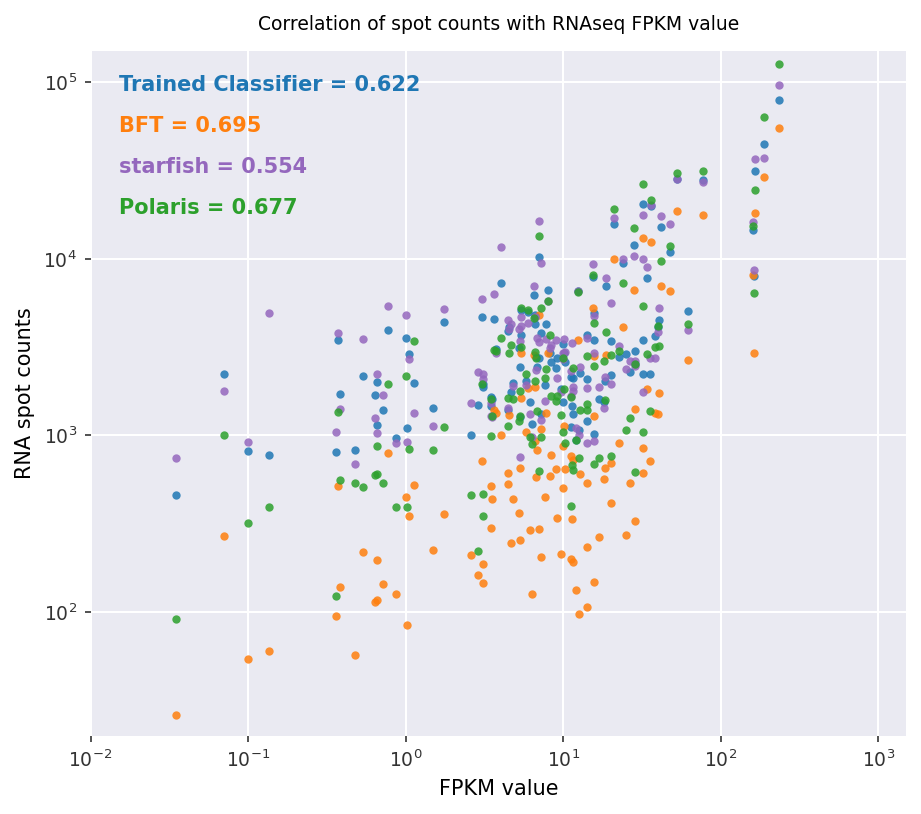

In [27]:
pooled = df_fpkm[["genes", "FPKM"]].copy().set_index("genes")   # adjust column names
pooled["model_counts"] = pd.Series(Counter(all_model_callouts)).reindex(pooled.index).fillna(0)
pooled["bft_counts"] = pd.Series(Counter(all_bft_callouts)).reindex(pooled.index).fillna(0)
all_starfish_callouts = df_starfish['target'].tolist()
pooled["starfish_counts"] = pd.Series(Counter(all_starfish_callouts)).reindex(pooled.index).fillna(0)
pooled["polaris_counts"] = pd.Series(Counter(all_polaris_callouts)).reindex(pooled.index).fillna(0)

datasets = {
    "model": pooled.rename(columns={"model_counts": "spot_count"}),
    "bft": pooled.rename(columns={"bft_counts": "spot_count"}),
    "starfish": pooled.rename(columns={"starfish_counts": "spot_count"}),
    'polaris': pooled.rename(columns={"polaris_counts": "spot_count"})
}
 
labels = {"model": "Trained Classifier", "bft": "BFT", "starfish": "starfish",
          "polaris": "Polaris"}

fig, ax, correlations = plotFPKMCorrelation(datasets, colours=colors, labels=labels,
                                            figsize= (6.24,5.52), xlim=(1e-2, 1e3+(1e3/2)), ylim=(20, 1e5+(1e5/2)))
fig.savefig(os.path.join(output_dir, 'FPKM_correlation_all_methods_LM50GS_tissue_p_crop_edge.svg'))

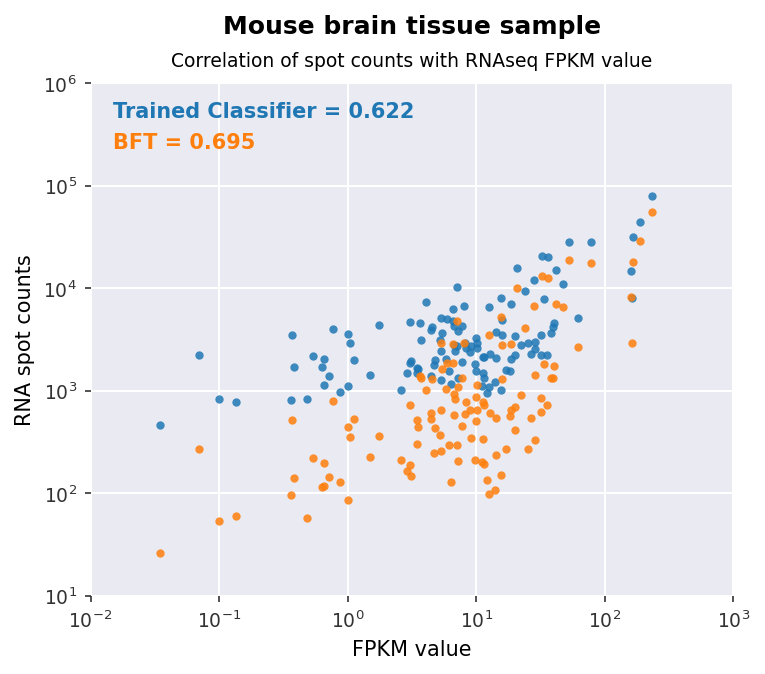

In [28]:
datasets_gs_bft = {
    "model": pooled.rename(columns={"model_counts": "spot_count"}),
    "bft":   pooled.rename(columns={"bft_counts": "spot_count"}),
}

labels_gs_bft = {"model": "Trained Classifier", "bft": "BFT"}

fig2, ax2, correlations_gs_bft = plotFPKMCorrelation(
    datasets_gs_bft,
    colours=colors,
    labels=labels_gs_bft,
    title='Mouse brain tissue sample'
)
fig2.savefig(os.path.join(output_dir, 'FPKM_correlation_GS_BFT_LM50GS_tissue.svg'))

In [29]:
pooled.sum()

FPKM                 2333.445
model_counts       671431.000
bft_counts         296620.000
starfish_counts    753904.000
polaris_counts     650194.000
dtype: float64

In [30]:
pooled.sum().iloc[1]/pooled.sum()

FPKM               287.742372
model_counts         1.000000
bft_counts           2.263607
starfish_counts      0.890605
polaris_counts       1.032663
dtype: float64

In [31]:
pooled.sum()/pooled.sum().iloc[1]

FPKM               0.003475
model_counts       1.000000
bft_counts         0.441773
starfish_counts    1.122832
polaris_counts     0.968371
dtype: float64